In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
np.random.seed(2)

students = 200
questions = 10

responses = np.random.randint(0, 2, (students, questions))

difficulty = np.random.rand(questions)

In [5]:
responses

array([[0, 1, 1, ..., 1, 0, 1],
       [0, 1, 1, ..., 1, 0, 0],
       [0, 0, 1, ..., 0, 1, 1],
       ...,
       [1, 0, 0, ..., 1, 0, 1],
       [0, 0, 0, ..., 1, 1, 0],
       [1, 0, 0, ..., 1, 0, 0]], shape=(200, 10))

In [6]:
df_resp = pd.DataFrame(
    responses,
    columns=[f"Q{i}" for i in range(questions)]
)

In [7]:
df_resp

,Q0,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9
0,0,1,1,0,0,1,0,1,0,1
1,0,1,1,1,1,1,1,1,0,0
2,0,0,1,1,1,0,0,0,1,1
3,1,0,0,1,0,0,1,1,1,0
4,0,0,0,1,1,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...
195,0,0,1,0,1,1,0,0,0,1
196,1,0,1,0,1,1,1,0,1,0
197,1,0,0,1,0,1,0,1,0,1
198,0,0,0,1,0,1,1,1,1,0


In [8]:
df_diff = pd.DataFrame({
    "Q": df_resp.columns,
    "difficulty": difficulty
})

In [9]:
df_diff

,Q,difficulty
0,Q0,0.621843
1,Q1,0.565579
2,Q2,0.152671
3,Q3,0.813437
4,Q4,0.983462
5,Q5,0.633575
6,Q6,0.581438
7,Q7,0.148591
8,Q8,0.276673
9,Q9,0.360523


In [10]:
score_simple = df_resp.sum(axis=1)

In [11]:
score_simple

0      5
1      7
2      5
3      5
4      4
      ..
195    4
196    6
197    5
198    5
199    5
Length: 200, dtype: int64

In [12]:
score_weighted = df_resp.mul(difficulty).sum(axis=1)

In [13]:
score_weighted

0      1.860939
1      3.878753
2      2.586766
3      2.441982
4      3.011912
         ...   
195    2.130231
196    3.249662
197    2.577969
198    2.453714
199    2.968909
Length: 200, dtype: float64

In [14]:
score_consistency = score_weighted - df_resp.var(axis=1)

In [15]:
score_consistency

0      1.583161
1      3.645419
2      2.308988
3      2.164204
4      2.745245
         ...   
195    1.863564
196    2.982995
197    2.300191
198    2.175936
199    2.691131
Length: 200, dtype: float64

In [16]:
df_scores = pd.DataFrame({
    "Simple": score_simple,
    "Weighted": score_weighted,
    "Consistency": score_consistency
})

In [17]:
df_scores

,Simple,Weighted,Consistency
0,5,1.860939,1.583161
1,7,3.878753,3.645419
2,5,2.586766,2.308988
3,5,2.441982,2.164204
4,4,3.011912,2.745245
...,...,...,...
195,4,2.130231,1.863564
196,6,3.249662,2.982995
197,5,2.577969,2.300191
198,5,2.453714,2.175936


In [18]:
ranks = df_scores.rank(ascending=False)

ranks

,Simple,Weighted,Consistency
0,103.5,155.0,157.0
1,27.0,22.0,22.0
2,103.5,110.0,110.0
3,103.5,123.0,124.0
4,150.5,67.0,67.0
...,...,...,...
195,150.5,137.0,137.0
196,60.0,48.0,48.0
197,103.5,113.0,113.0
198,103.5,121.0,122.0


In [19]:
correlation = df_scores.corr()

correlation

,Simple,Weighted,Consistency
Simple,1.000000,0.880386,0.879863
Weighted,0.880386,1.000000,0.999378
Consistency,0.879863,0.999378,1.000000


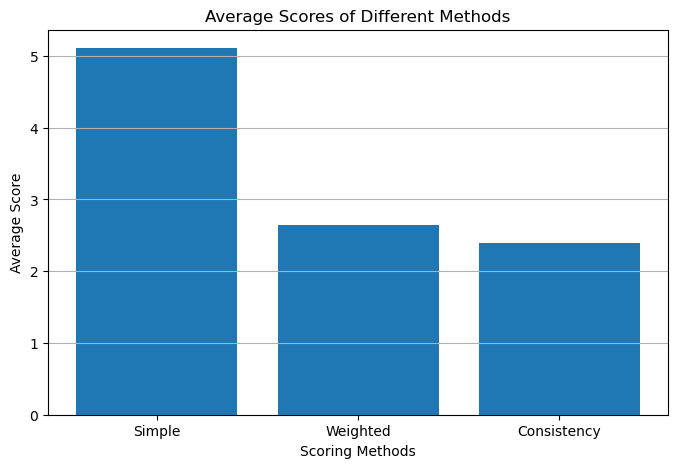

In [20]:
plt.figure(figsize=(8,5))

avg_scores = df_scores.mean()

plt.bar(avg_scores.index, avg_scores.values)

plt.xlabel("Scoring Methods")
plt.ylabel("Average Score")
plt.title("Average Scores of Different Methods")

plt.grid(axis='y')

plt.show()

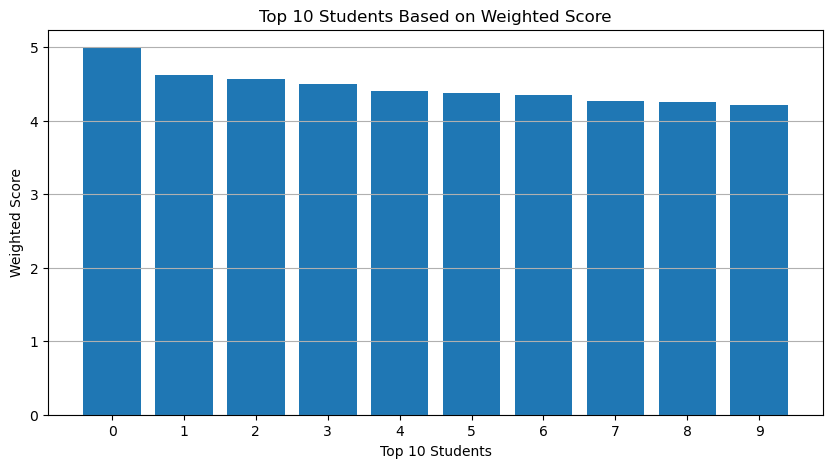

In [21]:
plt.figure(figsize=(10,5))

top_students = df_scores["Weighted"]\
    .sort_values(ascending=False)\
    .head(10)

plt.bar(range(10), top_students.values)

plt.xlabel("Top 10 Students")
plt.ylabel("Weighted Score")
plt.title("Top 10 Students Based on Weighted Score")

plt.xticks(range(10))

plt.grid(axis='y')

plt.show()

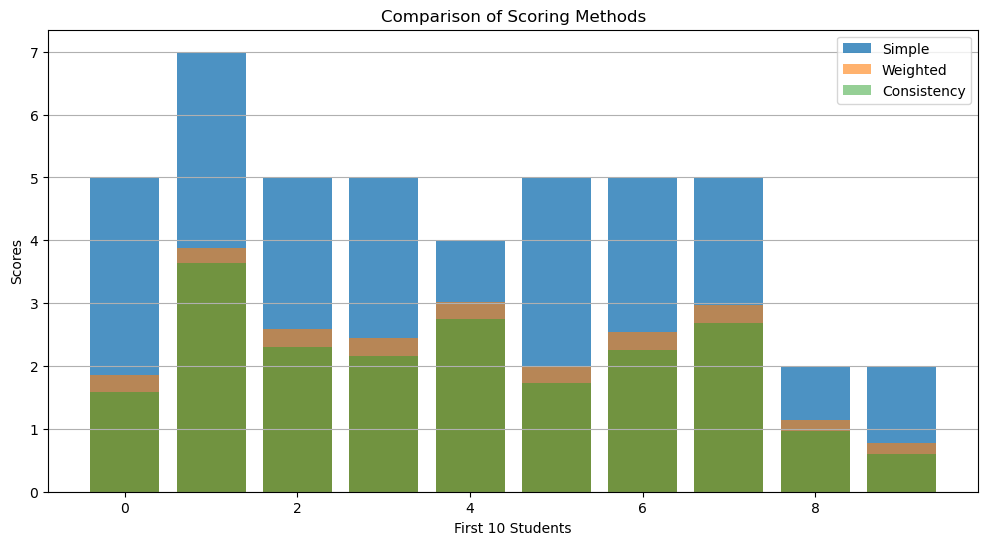

In [22]:
plt.figure(figsize=(12,6))

first10 = df_scores.head(10)

plt.bar(
    first10.index,
    first10["Simple"],
    label="Simple",
    alpha=0.8
)

plt.bar(
    first10.index,
    first10["Weighted"],
    label="Weighted",
    alpha=0.6
)

plt.bar(
    first10.index,
    first10["Consistency"],
    label="Consistency",
    alpha=0.5
)

plt.xlabel("First 10 Students")
plt.ylabel("Scores")
plt.title("Comparison of Scoring Methods")

plt.legend()

plt.grid(axis='y')

plt.show()

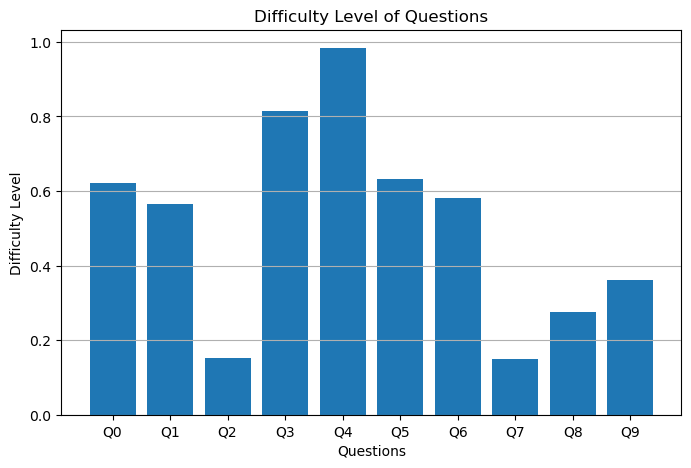

In [23]:
plt.figure(figsize=(8,5))

plt.bar(
    df_diff["Q"],
    df_diff["difficulty"]
)

plt.xlabel("Questions")
plt.ylabel("Difficulty Level")
plt.title("Difficulty Level of Questions")

plt.grid(axis='y')

plt.show()